**Mechanistic Interpretability: Binary Carry Detection**

Task: Investigate how a small neural network learns to detect a carry when adding two binary digits

The model receives two binary inputs and predicts 1 only when both inputs are 1 otherwise it predicts 0


**Methods shown in this notebook:**
* Training a small MLP and evaluate its predictions

* Visualizing hidden neuron activations

* PAblating individual neurons to test their causal contributions

* Stress testing a high activity neuron across all four possible inputs

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import random
import numpy as np

### Data Generation

In [3]:
#def generate_binary_data(n_samples=10000, seq_length=8):
def generate_binary_data(n_samples=10000, seq_length=2):    #changing length to 2 for carry logic 
    X = []
    y = []
    for _ in range(n_samples):
        binary_str = [random.choice([0, 1]) for _ in range(seq_length)]
        #label = sum(binary_str)
        label = int(sum(binary_str) == 2) #will only be 1 when both inputs are 2
        X.append(binary_str)
        y.append(label)
    return torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.long)

#seq_length = 8
#n_classes = seq_length + 1
seq_length = 2
n_classes = 2
X_train, y_train = generate_binary_data(2000, seq_length)
X_val, y_val = generate_binary_data(500, seq_length)

In [4]:
print(X_train[:10])
print(y_train[:10])

tensor([[1., 1.],
        [1., 1.],
        [0., 1.],
        [0., 0.],
        [1., 1.],
        [1., 1.],
        [0., 1.],
        [1., 1.],
        [0., 1.],
        [0., 0.]])
tensor([1, 1, 0, 0, 1, 1, 0, 1, 0, 0])


### Build a Tiny MLP (multilayer perceptron) Model

In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Updated Model for Regression
#class CountingMLP(nn.Module):
class CarryMLP(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, 1)  # Output is a single scalar

    def forward(self, x):
        h = F.relu(self.fc1(x))
        out = self.fc2(h)
        return out, h  # for interpretability

# Instantiate model
#model = CountingMLP(input_dim=seq_length, hidden_dim=10)
model = CarryMLP(input_dim=seq_length, hidden_dim=10)
print(model)

# Convert targets to float (regression labels)
y_train_reg = y_train.float().unsqueeze(1)
y_val_reg = y_val.float().unsqueeze(1)

# Training loop with MSE loss
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
criterion = nn.MSELoss()

losses = []
for epoch in range(100):
    model.train()
    out, _ = model(X_train)
    loss = criterion(out, y_train_reg)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

print("Final training loss:", losses[-1])

# Evaluation: Mean Absolute Error + Rounded Accuracy
model.eval()
with torch.no_grad():
    preds, _ = model(X_val)
    mae = torch.abs(preds - y_val_reg).mean().item()
    rounded_preds = torch.round(preds).squeeze().long()
    accuracy = (rounded_preds == y_val).float().mean().item()

print(f"Validation MAE: {mae:.2f}")
print(f"Rounded Accuracy: {accuracy:.2f}")


CarryMLP(
  (fc1): Linear(in_features=2, out_features=10, bias=True)
  (fc2): Linear(in_features=10, out_features=1, bias=True)
)


[transformers] Disabling PyTorch because PyTorch >= 2.4 is required but found 2.2.2
[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


Final training loss: 1.806037107598968e-05
Validation MAE: 0.00
Rounded Accuracy: 1.00


### Print Activations of a sample input

In [6]:
with torch.no_grad():
    #sample_input = torch.tensor([[1, 0, 1, 0, 1, 1, 0, 0]], dtype=torch.float32)
    #sample_input = torch.tensor([[1, 1]], dtype=torch.float32)
    sample_input = torch.tensor([
        [0, 0],
        [0, 1],
        [1, 0],
        [1, 1]
    ], dtype=torch.float32)
    logits, hidden = model(sample_input)

print(f"Sample Input: {sample_input}")
print(f"Hidden Layer Activations: {hidden}")
print(f"Output Logits: {logits}")
#rounded = round(logits.item())
rounded = torch.round(logits)
print(f"Rounded Prediction: {rounded}")


Sample Input: tensor([[0., 0.],
        [0., 1.],
        [1., 0.],
        [1., 1.]])
Hidden Layer Activations: tensor([[0.0000, 0.0000, 0.3262, 0.0066, 0.4735, 0.0125, 0.0000, 0.0000, 0.0000,
         0.7201],
        [0.0000, 0.6808, 0.0000, 0.6370, 1.2582, 0.5550, 0.0000, 0.0000, 0.0000,
         0.0609],
        [0.0000, 0.0000, 0.5470, 0.0000, 0.5913, 0.0000, 0.0000, 0.0000, 0.0000,
         0.7607],
        [0.0000, 0.0000, 0.0104, 0.0000, 1.3760, 0.0000, 0.0000, 0.0000, 0.0000,
         0.1014]])
Output Logits: tensor([[ 2.4638e-03],
        [-7.6827e-04],
        [-6.5164e-03],
        [ 1.0044e+00]])
Rounded Prediction: tensor([[0.],
        [-0.],
        [-0.],
        [1.]])


### Plot hidden activations across different numbers of 1s as input

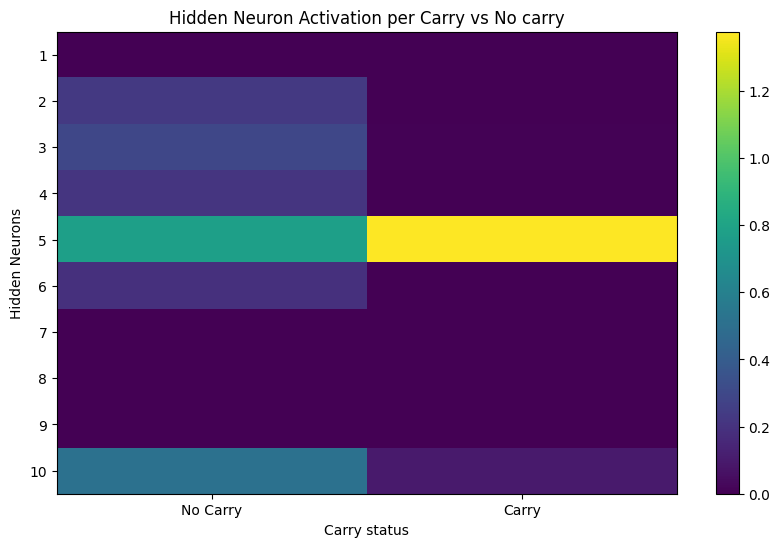

In [7]:
#counts = list(range(n_classes))
classes = [0, 1] #comparing no carry/carry instead of counting
avg_activations = torch.zeros((n_classes, 10))

#for c in counts:
for c in classes:    
    class_inputs = X_val[y_val == c]
    if class_inputs.shape[0] > 0:
        _, h = model(class_inputs)
        avg_activations[c] = h.mean(dim=0)

plt.figure(figsize=(10, 6))
activations_np = avg_activations.T.detach().numpy()
plt.imshow(activations_np, aspect='auto', cmap='viridis')
#plt.xlabel("Number of 1s in Input")
plt.xticks([0, 1], ["No Carry", "Carry"])
plt.yticks(range(10), range(1, 11))
plt.xlabel("Carry status")
plt.ylabel("Hidden Neurons")
#plt.title("Average Activation per Hidden Neuron by Count")
plt.title("Hidden Neuron Activation per Carry vs No carry")
plt.colorbar()
plt.show()

#### **What does this plot show us?**

##### *hidden neuron analysis*
The heatmap is comparing avg hidden neuron activations for carry and noncarry inputs. There are neurons that respond more to carry which indicates that the network learns different internal features. That said, 
activation is one feature, it doesn't tell us whether the neuron is moving the needle in the prediction. So, will leverage neuron ablation to test real time contribution

_____________________

### Neuron Ablation (single neuron)

In [10]:
# Sample input to test
#test_input = torch.tensor([[1, 0, 1, 1, 0, 0, 1, 0]], dtype=torch.float32)  # Example: 4 ones
test_input = torch.tensor([[1, 1]], dtype=torch.float32) #model only binary 
#true_count = int(test_input.sum().item())
true_carry = int(test_input.sum().item() == 2) #carrying the value not the sum over

# Baseline prediction
model.eval()
with torch.no_grad():
    baseline_output, _ = model(test_input)
    baseline_pred = baseline_output.item()

# Zero out one neuron in the hidden layer (e.g., neuron 3)
#neuron_to_zero = 3
neuron_to_zero = 6 #so far neuron 7 shows the strongest activation during carry, so using index 6 

# Manually run forward pass with neuron ablated
with torch.no_grad():
    h = F.relu(model.fc1(test_input))
    h[:, neuron_to_zero] = 0  # zeroing neuron
    modified_output = model.fc2(h)
    modified_pred = modified_output.item()


#print(f"True count: {true_count}")
print(f"True carry: {true_carry}")
#print(f"Prediction (normal): {baseline_pred:.2f}")
#print(f"Prediction (with neuron {neuron_to_zero} zeroed): {modified_pred:.2f}")
    # 2 is too flat and not showing change, expanding for more visibility
print(f"Prediction (normal): {baseline_pred:.6f}")
print(f"Prediction (with neuron {neuron_to_zero} zeroed): {modified_pred:.6f}")



delta = modified_pred - baseline_pred
if delta > 0:
    print(f"➕ Prediction increased by {delta:.2f}")
elif delta < 0:
    print(f"➖ Prediction decreased by {abs(delta):.2f}")
else:
    print("⚖️ No change in prediction")


True carry: 1
Prediction (normal): 1.004367
Prediction (with neuron 6 zeroed): 1.004367
⚖️ No change in prediction


#### **What does the ablation tell us?**

##### *single neuron analysis*
I initially tested neuron 6 since the activation analysis showed it could be important, but after disabling it, it didn't produce a change in the carry prediction. This indicated that the strong activation didn't translate into direct causal significance in the final decision

### Neuron Ablation (sweep of neurons)

True carry: 1, Baseline prediction: 1.004367


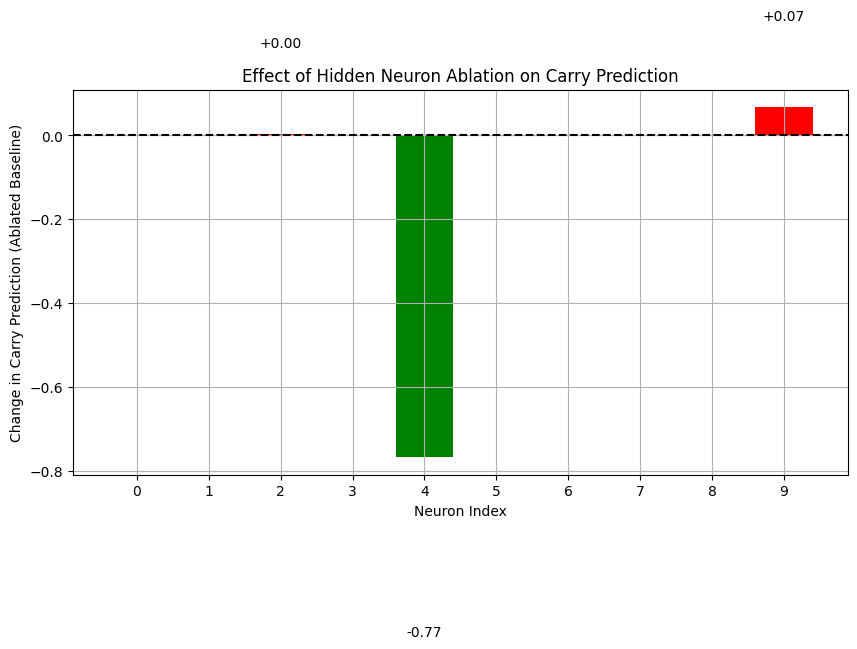

Neuron 2 → Prediction increased by 0.00
Neuron 4 → Prediction decreased by 0.77
Neuron 9 → Prediction increased by 0.07


In [13]:
# Sample input to test
#test_input = torch.tensor([[1, 0, 1, 1, 0, 0, 1, 0]], dtype=torch.float32)
test_input = torch.tensor([[1, 1]], dtype=torch.float32)
#true_count = int(test_input.sum().item())
true_carry = int(test_input.sum().item() == 2)

# Baseline prediction
model.eval()
with torch.no_grad():
    baseline_output, _ = model(test_input)
    baseline_pred = baseline_output.item()

#print(f"🧾 True count: {true_count}, Baseline prediction: {baseline_pred:.2f}")
print(f"True carry: {true_carry}, Baseline prediction: {baseline_pred:.6f}")

# Sweep: get signed change in scalar prediction
neuron_indices = list(range(model.fc1.out_features))
signed_deltas = []

for i in neuron_indices:
    with torch.no_grad():
        h = F.relu(model.fc1(test_input))
        h[:, i] = 0  # zero out neuron i
        mod_output = model.fc2(h)
        mod_pred = mod_output.item()
        signed_deltas.append(mod_pred - baseline_pred)

# Plotting signed prediction change per neuron
plt.figure(figsize=(10, 5))
colors = ['green' if d < 0 else 'red' if d > 0 else 'gray' for d in signed_deltas]

plt.bar(neuron_indices, signed_deltas, color=colors)
plt.axhline(0, color='black', linestyle='--')
plt.xticks(neuron_indices)
plt.xlabel("Neuron Index")
#plt.ylabel("Prediction Change (Modified - Original)")
plt.ylabel("Change in Carry Prediction (Ablated Baseline)")
#plt.title("Effect of Zeroing Hidden Neurons on Predicted Count")
plt.title("Effect of Hidden Neuron Ablation on Carry Prediction")
plt.grid(True)

# Annotatation
for i, d in enumerate(signed_deltas):
    if abs(d) > 1e-3:
        plt.text(i, d + (0.2 if d > 0 else -0.4), f"{d:+.2f}",
                 ha='center', va='bottom' if d > 0 else 'top')

plt.show()

# Summary
for i, d in enumerate(signed_deltas):
    if abs(d) > 1e-3:
        direction = "increased" if d > 0 else "decreased"
        print(f"Neuron {i} → Prediction {direction} by {abs(d):.2f}")


In [21]:
# looking for every possible input combo
test_inputs = torch.tensor([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
], dtype=torch.float32)


with torch.no_grad():
    baseline_outputs, _ = model(test_inputs)
    print("Baseline:", baseline_outputs.squeeze().numpy().round(4))

with torch.no_grad():
    h = F.relu(model.fc1(test_inputs))
    h[:, 4] = 0
    ablated_outputs = model.fc2(h)
print("ablated:", ablated_outputs.squeeze().numpy().round(4))

Baseline: [ 2.5000e-03 -8.0000e-04 -6.5000e-03  1.0044e+00]
ablated: [-0.2616 -0.7025 -0.3363  0.2369]


#### **What does the sweep of neuron ablations tell us?**

##### *Which neurons had the most impact on predictions?*

Neuron 4 had the most impact on predictions, when disabled it dropped the prediction for [1,1] from 1.0044 to 0.2369. It ended up changing the rounded classification from carry to no carry. Neuron 9 also had a significant impact where it increased the prediction by around ~.07 when it was disabled. I ended up ablating across all 4 possible inputs and the predictions decreased in all of them including in the inputs wihout carry. So neuron 4 overall contributed to the output but doesn't actaully detect carry.

##### *Are there redundant neurons (zeroing them causes no change)?*

Yes, there were a lot of neurons with no effect when individually ablated. One example is neuron 6

Limitation: Since the model only has 4 inputs, this project overall did show the behavioral but it didnt lead to a definitive caryr detection source

